# Технологии нейросетевых вычислений



##ЛР4. Рекуррентные нейронные сети. Предобработка текста (10 баллов + 2 балла бонусных)

# О формате сдачи

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

# Задание

В этом задании будем определять тональность сообщений, используя техники предобработки текста и рекуррентные сети.

Установим и импортируем необходимые библиотеки.

In [1]:
%pip install -q pymorphy2 nltk

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import pandas as pd
from collections import defaultdict
import time

import re
import pymorphy2
import nltk
from nltk.corpus import stopwords

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

### Точки сохранения

Сессия Colab может отключиться (простой, лимит GPU, обрыв интернета), и всё, что было в памяти, пропадёт. Поэтому веса моделей сохраняются на **Google Drive**:

* базовая модель сохраняется после обучения, при повторном запуске ноутбука она загружается, а не обучается заново;
* улучшенные модели (задание 6) сохраняются **после каждой эпохи** вместе с оптимизатором и планировщиком lr, при повторном запуске обучение продолжается с той эпохи, на которой оборвалось.

После отключения достаточно заново выполнить все ячейки (`Runtime → Run all`). Если вы поменяли предобработку или гиперпараметры, удалите папку с чекпоинтами (или поменяйте `CKPT_DIR`), иначе загрузятся старые веса.

In [3]:
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    CKPT_DIR = '/content/drive/MyDrive/tnc_lab4_checkpoints'
else:
    CKPT_DIR = 'checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)
print('Чекпоинты:', CKPT_DIR)
print('Уже сохранено:', sorted(os.listdir(CKPT_DIR)))


def save_atomic(obj, path):
    # пишем во временный файл и подменяем: обрыв посреди записи не испортит уже сохранённый чекпоинт
    tmp_path = path + '.tmp'
    torch.save(obj, tmp_path)
    os.replace(tmp_path, path)

Mounted at /content/drive
Чекпоинты: /content/drive/MyDrive/tnc_lab4_checkpoints
Уже сохранено: []


Будем классифицировать тон комментариев, связанных с коронавирусом. Давайте скачаем их с диска

In [4]:
# Архив уже лежит рядом с ноутбуком; если нет — скачиваем
import zipfile
if not os.path.exists('coronavirus_archive.zip'):
    !pip install -q gdown
    !gdown https://drive.google.com/uc?id=145ZCFU-b65Xbjsh16fPepF_N66X0kZj2
if not os.path.exists('Corona_NLP_train.csv'):
    zipfile.ZipFile('coronavirus_archive.zip').extractall('.')

Downloading...
From: https://drive.google.com/uc?id=145ZCFU-b65Xbjsh16fPepF_N66X0kZj2
To: /content/coronavirus_archive.zip
100% 4.60M/4.60M [00:00<00:00, 20.9MB/s]


In [5]:
df_train = pd.read_csv("Corona_NLP_train.csv", encoding='ISO-8859-1')
df_test = pd.read_csv("Corona_NLP_test.csv", encoding='ISO-8859-1')

df_train.head()

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive
3,3802,48754,NaN,16-03-2020,My food stock is not the only one which is emp...,Positive
4,3803,48755,NaN,16-03-2020,"Me, ready to go at supermarket during the #COV...",Extremely Negative


Нам понадобятся колонки `OriginalTweet` и `Sentiment`.

In [6]:
df_train = df_train[['OriginalTweet', 'Sentiment']]
df_test = df_test[['OriginalTweet', 'Sentiment']]

df_train = df_train.dropna()
df_test = df_test.dropna()

df_train['Sentiment'].value_counts()

,count
Sentiment,
Positive,11422
Negative,9917
Neutral,7713
Extremely Positive,6624
Extremely Negative,5481


Давайте рассмотрим на один из твиттов в данных:

In [7]:
print(f"TWEET TEXT: {df_train['OriginalTweet'].iloc[0]}")
print(f"CATEGORY: {df_train['Sentiment'].iloc[0]}")

TWEET TEXT: @MeNyrbie @Phil_Gahan @Chrisitv https://t.co/iFz9FAn2Pa and https://t.co/xX6ghGFzCC and https://t.co/I2NlzdxNo8
CATEGORY: Neutral


Как вы можете заметить, текст может вообще не содержать хоть сколько-нибудь полезной информации и состоять исключительно из ссылок и отметок

In [8]:
print(f"TWEET TEXT: {df_train['OriginalTweet'].iloc[1]}")
print(f"CATEGORY: {df_train['Sentiment'].iloc[1]}")

TWEET TEXT: advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order
CATEGORY: Positive


А могут быть и вполне себе осмысленные предложения.

In [9]:
print(f"TWEET TEXT: {df_train['OriginalTweet'].iloc[4]}")
print(f"CATEGORY: {df_train['Sentiment'].iloc[4]}")





#CoronavirusFrance #restezchezvous #StayAtHome #confinement https://t.co/usmuaLq72n
CATEGORY: Extremely Negative


А иногда в тексте содержится и то, и другое. Возможно, внутри твитов есть и другие паттерны. Например, обратите внимание на хештеги.

## <font color='DarkOrange'> **Задание 1 [1 балл]** </font>

Выполним токенизацию (разделение текста на токены - например, отдельные слова являются токенами для предложения). Далее токены нужно перевести в формат числовых векторов (выполнить векторизацию). Иногда токенизацию+векторизацию заменяют в речи для краткости одним из этих слов - как синоним предобработки.

Напишите функцию `tokenize`, которая преобразовывает текст в список токенов-слов. При этом:

1. Текст должен быть приведен к нижнему регистру.
2. Должны быть удалены стоп-слова.
3. Возможно, должны быть удалены некоторые конкретные символы (на ваше усмотрение)

Используем `Natural Language Toolkit`

In [10]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
punctuation = re.compile(r'[^a-zA-Z\s]')

url_re = re.compile(r'https?://\S+|www\.\S+')
mention_re = re.compile(r'@\w+')
amp_re = re.compile(r'&amp;?')


def tokenize(text):
    text = text.lower()
    text = url_re.sub(' ', text)       # ссылки не несут тональности
    text = mention_re.sub(' ', text)   # @упоминания — имена пользователей
    text = amp_re.sub(' ', text)       # html-сущность &amp;
    text = text.replace('#', ' ')      # хештег #panicbuying -> слово panicbuying
    text = punctuation.sub(' ', text)  # всё, кроме латиницы и пробелов (цифры, пунктуация, битая кодировка)
    tokens = [t for t in text.split() if t not in stop_words and len(t) > 1]
    return tokens


print(tokenize(df_train['OriginalTweet'].iloc[4]))

['ready', 'go', 'supermarket', 'covid', 'outbreak', 'paranoid', 'food', 'stock', 'litteraly', 'empty', 'coronavirus', 'serious', 'thing', 'please', 'panic', 'causes', 'shortage', 'coronavirusfrance', 'restezchezvous', 'stayathome', 'confinement']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Преобразуем нужные колонки.

In [11]:
df_train['tokenized'] = df_train['OriginalTweet'].apply(tokenize)
df_test['tokenized'] = df_test['OriginalTweet'].apply(tokenize)

In [12]:
assert isinstance(df_train['tokenized'].iloc[0], list)

## <font color='DarkOrange'> **Задание 2 [2 балла]** </font>

Теперь создайте словарь со всеми токенами в тексте и их частотами встречаемости:

In [13]:
counter_tokens = defaultdict(int)
for tokens in df_train['tokenized']:  # словарь строим только по train, чтобы не подглядывать в test
    for token in tokens:
        counter_tokens[token] += 1

print(f'Уникальных токенов: {len(counter_tokens)}')
sorted(counter_tokens.items(), key=lambda x: -x[1])[:15]

Уникальных токенов: 43030


[('covid', 23222),
 ('coronavirus', 18209),
 ('prices', 7958),
 ('food', 7177),
 ('supermarket', 7094),
 ('store', 6932),
 ('grocery', 6284),
 ('people', 5624),
 ('consumer', 4646),
 ('shopping', 3625),
 ('online', 3452),
 ('pandemic', 3291),
 ('get', 2877),
 ('need', 2718),
 ('workers', 2610)]

Для работы с текстами необходимо зарезервировать два специальных токена:

1. `<pad>` для токена, означающего паддинг
1. `<unk>` для токенов, которые отсутствуют в словаре

Добавьте указанные токены в ваш словарь.

In [14]:
specials = ['<pad>', '<unk>']
for special in specials:
    counter_tokens[special] = 0  # частота не важна: make_dict ставит спецтокены в начало словаря

Теперь напишите функцию, которая принимает на вход словарь "слово-частота", выдаёт список токенов (слов) itos, которые упорядочены по убыванию частоты встречаемости, а также словарь "слово-ранг" как enumerate для itos. Ограничим эти контейнеры длиной max_size

In [15]:
def make_dict(counter, specials, max_size=5000):
    words = sorted((w for w in counter if w not in specials), key=lambda w: -counter[w])
    itos = list(specials) + words[:max_size - len(specials)]
    stoi = {word: idx for idx, word in enumerate(itos)}
    return stoi, itos

Воспользуемся функцией, чтобы получить нужный словарь и список.

In [16]:
stoi, itos = make_dict(counter_tokens, specials)
stoi['<pad>']

0

## <font color='DarkOrange'> **Задание 3 [2 балла]** </font>

Наконец вам необходимо создать обёртку-датасет для данных.

Уже добавлены несколько опций, которые понадобятся далее:

1. Ограничение на максимальную длину текста в токенах. Если текст оказывается длиннее, то последние токены отбрасываются.
2. Возможность добавить специальные токены <sos>, <eos> в начало и конец токенизированного текста.

Заполните оставшиеся строки. Лейблы необходимо перекодировать в числовой вид и сохранить в виде тензора.

In [17]:
class ReviewDataset(Dataset):
    def __init__(self, data,
                 max_len,
                 stoi, itos,
                 token_column='tokenized',
                 label_column='Sentiment',
                 pad_sos=False, pad_eos=False):
        """
        :param data: data
        :param int max_len: Maximum length of tokenized text
        :param bool pad_sos: If True pad sequence at the beginning with <sos>
        :param bool pad_eos: If True pad sequence at the end with <eos>
        """
        super().__init__()

        self.stoi = stoi.copy()
        self.itos = itos.copy()
        self.pad_sos = pad_sos
        if self.pad_sos:
            self.itos.append('<sos>')
            self.sos_id = len(self.itos) - 1  # индекс только что добавленного токена
            self.stoi['<sos>'] = self.sos_id
        self.pad_eos = pad_eos
        if self.pad_eos:
            self.itos.append('<eos>')
            self.eos_id = len(self.itos) - 1
            self.stoi['<eos>'] = self.eos_id

        self.max_len = max_len
        self.data = data.copy()

        self.texts = []
        self.tokens = []

        sentiment_mapping = {
            'Extremely Positive': 4,
            'Positive': 3,
            'Neutral': 2,
            'Negative': 1,
            'Extremely Negative': 0}

        # используйте sentiment_mapping
        self.labels = torch.tensor(data[label_column].map(sentiment_mapping).values, dtype=torch.long)
        self.tokens_len = []

        for i, row in data.iterrows():
            self.texts.append(row['OriginalTweet'])
            ids = self.lookup_indices(row[token_column][:max_len])  # обрезаем хвост длинных текстов
            if len(ids) == 0:
                ids = [self.stoi['<unk>']]  # твит только из ссылок/упоминаний -> один <unk>, чтобы не терять объект
            if self.pad_sos:
                ids = [self.sos_id] + ids
            if self.pad_eos:
                ids = ids + [self.eos_id]
            self.tokens.append(torch.tensor(ids, dtype=torch.long)) # сами токены
            self.tokens_len.append(torch.tensor(len(ids), dtype=torch.long)) # кол-во токенов

    def __getitem__(self, idx):
        """
        :param int idx: index of object in dataset
        :return dict: Dictionary with all useful object data
            {
                'text' str: unprocessed text,
                'label' torch.tensor(dtype=torch.long): sentiment of the text (0 for negative, 1 for positive)
                'tokens' torch.tensor(dtype=torch.long): tensor of tokens ids for the text
                'tokens_len' torch.tensor(dtype=torch.long): number of tokens
            }
        """
        return {
            'text': self.texts[idx],
            'label': self.labels[idx],
            'tokens': self.tokens[idx],
            'tokens_len': self.tokens_len[idx]}

    def __len__(self):
        """
        :return int: number of objects in dataset
        """
        return len(self.data)

    def lookup_indices(self, text_list):
      """
      :return list: List with indices for each token in token_list with '<unk>' for unknown tokens
      """
      return  [self.stoi.get(token, self.stoi['<unk>']) for token in text_list]


In [18]:
train_dataset = ReviewDataset(df_train, 200, stoi, itos)
test_dataset = ReviewDataset(df_test, 200, stoi, itos)

Посмотрим, как выглядит объект в датасете:

In [19]:
test_dataset[0]

{'text': 'TRENDING: New Yorkers encounter empty supermarket shelves (pictured, Wegmans in Brooklyn), sold-out online grocers (FoodKick, MaxDelivery) as #coronavirus-fearing shoppers stock up https://t.co/Gr76pcrLWh https://t.co/ivMKMsqdT1',
 'label': tensor(0),
 'tokens': tensor([2024,   33,    1,    1,  132,    6,   50,    1,    1, 3405,  471,   12,
         1812,    1,    1,    3,    1,  238,   27]),
 'tokens_len': tensor(19)}

In [20]:
assert set(test_dataset[0].keys()) == set(['text', 'label', 'tokens', 'tokens_len'])

## <font color='DarkOrange'> **Задание 4 [2 балла]** </font>

Теперь нужно создать `DataLoader` для данных. Зададим кастомную функцию `collate_fn` - как объединить сэмплы в батч. Чтобы объединить несколько тензоров разной длины в один, воспользуйтесь функцией `torch.nn.utils.rnn.pad_sequence`.

In [21]:
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch, padding_value, batch_first=False):
    batch = [elem for elem in batch if elem['tokens_len'].item() > 0]
    if len(batch) == 0:
        raise ValueError("Batch contains only empty sequences.")

    labels = [elem['label'].item() for elem in batch]
    texts = [elem['text'] for elem in batch]
    tokens = [elem['tokens'] for elem in batch]
    tokens_lens = [elem['tokens_len'].item() for elem in batch]
    tokens = pad_sequence(tokens, batch_first=batch_first, padding_value=padding_value)

    if not batch_first:
        tokens = tokens.transpose(0, 1)

    return {
        'labels': torch.tensor(labels, dtype=torch.long),
        'tokens': tokens,
        'tokens_lens': torch.tensor(tokens_lens, dtype=torch.long),
        'texts': texts
    }

Наконец создадим даталоадеры.

In [22]:
from functools import partial

new_col = partial(collate_fn, padding_value=stoi['<pad>'], batch_first=False)

test_dataloader = DataLoader(test_dataset, batch_size=64,
                             collate_fn=new_col, shuffle=False, num_workers=0)
train_dataloader = DataLoader(train_dataset, batch_size=64,
                              collate_fn=new_col, shuffle=True, num_workers=0)

Давайте посмотрим на какой-нибудь батч:

In [23]:
batch = next(iter(test_dataloader))
print(batch.keys())
print(f"labels: {batch['labels']}")
print(f"tokens: {batch['tokens']}")
print(f"tokens_lens: {batch['tokens_lens']}")

dict_keys(['labels', 'tokens', 'tokens_lens', 'texts'])
labels: tensor([0, 3, 4, 1, 2, 2, 3, 2, 0, 4, 3, 0, 0, 4, 3, 0, 4, 2, 3, 4, 1, 4, 4, 4,
        0, 3, 1, 1, 1, 3, 1, 4, 0, 0, 2, 0, 1, 2, 1, 4, 3, 1, 2, 3, 3, 4, 4, 0,
        0, 0, 0, 2, 1, 4, 0, 1, 1, 3, 3, 2, 0, 0, 4, 0])
tokens: tensor([[2024,   33,    1,  ...,    0,    0,    0],
        [ 118,   26,   19,  ...,    0,    0,    0],
        [ 118,  195, 1619,  ...,    0,    0,    0],
        ...,
        [4024,    1, 3210,  ...,    0,    0,    0],
        [1040,    3,    2,  ...,    0,    0,    0],
        [ 354,   32,    4,  ...,    0,    0,    0]])
tokens_lens: tensor([19, 14,  5, 27, 23, 17,  6, 18, 26, 18, 17, 18, 25, 24, 17, 21, 19, 16,
        24, 28, 23, 22, 24, 19, 25, 18, 16, 31, 22, 16, 24, 13, 24, 35, 12, 33,
        27, 19, 25, 27, 21, 23, 24, 12, 15, 27, 19, 17, 29, 27, 21, 20, 22, 21,
        24, 30,  8,  8, 18, 13, 28, 26, 23, 23])



Нейросеть будет обрабатывать входную последовательность по словам (word level), имея стандартную рекуррентную архитектуру для классификации:

1. Слой представлений, превращающий id токена в вектор-эмбеддинг этого слова
2. Слой RNN
3. Полносвязный слой, предсказывающий выход по последнему скрытому состоянию

Допишите код (???) и прокомментируйте суть и назначение слоя с именем attention

In [24]:
class RNNClassifier(nn.Module):
    def __init__(self, embedding_dim, hidden_size, output_size, vocab, rec_layer=nn.LSTM, num_layers=2, dropout=0.3, bidirectional=True):
        super(RNNClassifier, self).__init__()
        self.vocab = vocab
        self.hidden_size = hidden_size
        self.embedding_dim = embedding_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(len(vocab), embedding_dim, padding_idx=vocab['<pad>'])

        self.rnn = rec_layer(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional,
            batch_first=True,  # collate_fn отдаёт тензор [batch, seq_len]
        )

        self.attention = nn.Linear(hidden_size * (2 if bidirectional else 1), 1)
        self.fc = nn.Linear(hidden_size * (2 if bidirectional else 1), output_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, tokens, tokens_lens):
        embedded = self.embedding(tokens)
        embedded = self.dropout(embedded)
        packed_output, (hidden, cell) = self.rnn(embedded)

        if self.bidirectional:
            hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            hidden = hidden[-1]

        attn_weights = torch.sigmoid(self.attention(hidden))  # [batch, 1], скаляр в (0, 1) на объект
        hidden = hidden * attn_weights
        hidden = self.dropout(hidden)
        output = self.fc(hidden)

        return output

**Про слой `attention`.** `nn.Linear(2·hidden, 1)` + сигмоида по итоговому скрытому состоянию даёт одно число $a\in(0,1)$ на каждый объект, и на него умножается весь вектор `hidden`: $h' = \sigma(w^\top h + b)\cdot h$.

По сути это не attention в классическом смысле (Bahdanau/Luong), а **гейт** — обучаемое масштабирование итогового представления (похоже на гейты в LSTM/GRU или squeeze-and-excitation). Сеть может «приглушить» представление, в котором она не уверена, что уменьшает модуль логитов и смягчает softmax.

Настоящее attention для классификации считает веса **по всем шагам последовательности**: $\alpha_t = \mathrm{softmax}_t(w^\top o_t)$ по выходам RNN $o_t$ (с маскированием `<pad>`), и итоговый вектор — взвешенная сумма $\sum_t \alpha_t o_t$. Тогда модель сама выбирает важные слова (например, *panic*, *great*), а не опирается только на последнее состояние. Такой вариант мы пробуем в задании 6.

In [25]:
if torch.cuda.is_available():
    device = 'cuda'
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

Using device: cuda


## <font color='DarkOrange'> **Задание 5 [2 балла]** </font>

Также дозаполните необходимые строки в `train_epoch` и `evaluate`.

In [26]:
def train_epoch(dataloader, model, loss_fn, optimizer, device):
    model.train()
    for idx, data in enumerate(dataloader):
        tokens = data['tokens'].to(device)
        tokens_lens = data['tokens_lens'].to(device)
        labels = data['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(tokens, tokens_lens)
        loss = loss_fn(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # защита от взрыва градиентов в RNN
        optimizer.step()


def evaluate(dataloader, model, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_accuracy = 0.0
    with torch.no_grad():
        for idx, data in enumerate(dataloader):
            tokens = data['tokens'].to(device)
            tokens_lens = data['tokens_lens'].to(device)
            labels = data['labels'].to(device)

            outputs = model(tokens, tokens_lens)
            total_loss += loss_fn(outputs, labels).item() * labels.size(0)  # loss_fn усредняет по батчу
            total_accuracy += (outputs.argmax(dim=1) == labels).sum().item()

    return total_loss / len(dataloader.dataset), total_accuracy / len(dataloader.dataset)

def train(
    train_loader, test_loader, model, loss_fn, optimizer, device, num_epochs
):
    test_losses = []
    train_losses = []
    test_accuracies = []
    train_accuracies = []
    time_it = []
    start = time.time()
    for epoch in range(num_epochs):
        start = time.time()
        train_epoch(train_loader, model, loss_fn, optimizer, device)
        train_loss, train_acc = evaluate(train_loader, model, loss_fn, device)
        train_accuracies.append(train_acc)
        train_losses.append(train_loss)

        test_loss, test_acc = evaluate(test_loader, model, loss_fn, device)
        test_accuracies.append(test_acc)
        test_losses.append(test_loss)
        time_it.append(time.time() - start)

        print(
            'Epoch: {0:d}/{1:d}. Loss (Train/Test): {2:.3f}/{3:.3f}. Accuracy (Train/Test): {4:.3f}/{5:.3f}'.format(
                epoch + 1, num_epochs, train_losses[-1], test_losses[-1], train_accuracies[-1], test_accuracies[-1]
            )
        )
    return train_losses, train_accuracies, test_losses, test_accuracies, time_it

Создайте модель, функцию потерь и оптимизатор.
Допишите код (???)

In [27]:
from torch.optim import AdamW

In [28]:
embedding_dim = 128
hidden_size = 256
output_size = 5
model_lstm = RNNClassifier(embedding_dim, hidden_size, output_size, stoi)
model_lstm.to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = AdamW(model_lstm.parameters(), lr=0.001, weight_decay=1e-4)

Обучите модель:

In [29]:
baseline_path = os.path.join(CKPT_DIR, 'baseline_lstm.pt')

if os.path.exists(baseline_path):
    ckpt = torch.load(baseline_path, map_location=device, weights_only=False)
    assert ckpt['itos'] == itos, 'Словарь изменился: удалите baseline_lstm.pt и обучите модель заново'
    model_lstm.load_state_dict(ckpt['model'])
    train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = ckpt['history']
    print(f'Модель загружена из {baseline_path}, история обучения:')
    for epoch in range(len(train_losses_pure)):
        print(
            'Epoch: {0:d}/{1:d}. Loss (Train/Test): {2:.3f}/{3:.3f}. Accuracy (Train/Test): {4:.3f}/{5:.3f}'.format(
                epoch + 1, len(train_losses_pure), train_losses_pure[epoch], test_losses_pure[epoch],
                train_accuracies_pure[epoch], test_accuracies_pure[epoch]
            )
        )
else:
    train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
        train_dataloader, test_dataloader, model_lstm, loss_fn, optimizer, device, 10
    )
    save_atomic({
        'model': model_lstm.state_dict(),
        'itos': itos,
        'history': (train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure),
    }, baseline_path)

Epoch: 1/10. Loss (Train/Test): 1.079/1.165. Accuracy (Train/Test): 0.560/0.518
Epoch: 2/10. Loss (Train/Test): 0.840/1.012. Accuracy (Train/Test): 0.682/0.618
Epoch: 3/10. Loss (Train/Test): 0.709/0.904. Accuracy (Train/Test): 0.748/0.674
Epoch: 4/10. Loss (Train/Test): 0.642/0.886. Accuracy (Train/Test): 0.776/0.688
Epoch: 5/10. Loss (Train/Test): 0.555/0.849. Accuracy (Train/Test): 0.806/0.696
Epoch: 6/10. Loss (Train/Test): 0.505/0.835. Accuracy (Train/Test): 0.821/0.702
Epoch: 7/10. Loss (Train/Test): 0.451/0.836. Accuracy (Train/Test): 0.840/0.712
Epoch: 8/10. Loss (Train/Test): 0.397/0.840. Accuracy (Train/Test): 0.859/0.712
Epoch: 9/10. Loss (Train/Test): 0.347/0.884. Accuracy (Train/Test): 0.875/0.712
Epoch: 10/10. Loss (Train/Test): 0.320/0.905. Accuracy (Train/Test): 0.884/0.710


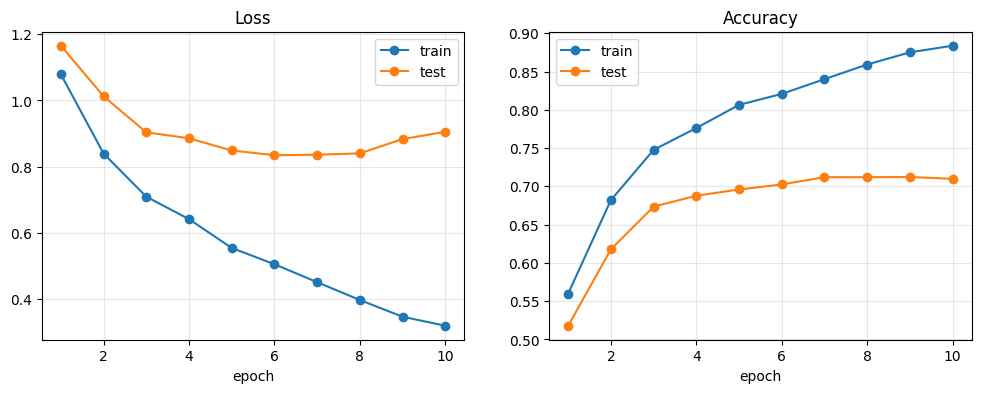

In [30]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses_pure) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, train_losses_pure, 'o-', label='train')
axes[0].plot(epochs_range, test_losses_pure, 'o-', label='test')
axes[0].set_title('Loss')
axes[1].plot(epochs_range, train_accuracies_pure, 'o-', label='train')
axes[1].plot(epochs_range, test_accuracies_pure, 'o-', label='test')
axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

Давайте посмотрим на качество, которое у нас получилось.

In [31]:
def return_outputs(model, dataloader):
    model.eval()

    labels_all = []
    outputs_all = []
    with torch.no_grad():
        for idx, data in enumerate(dataloader):
            tokens, tokens_lens = data['tokens'].to(device), data['tokens_lens'].to(device)
            labels = data['labels']
            labels_all.extend(labels)
            outputs = model(tokens, tokens_lens).to('cpu')
            outputs_all.extend(outputs)
    return torch.concat([l.reshape(1) for l in labels_all]), torch.vstack(outputs_all)

In [32]:
labels, outputs_lstm = return_outputs(model_lstm, test_dataloader)

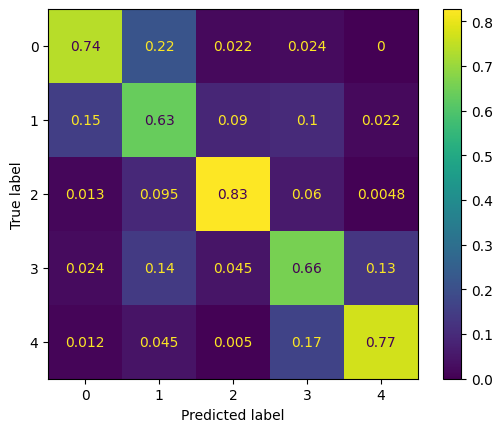

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(labels, torch.argmax(outputs_lstm, dim=1), labels=np.unique(labels),
                      normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

## <font color='MediumSeaGreen'> **Задание 6 [1 + 2 баллa]** </font>

Вычислите f1-меру. Весьма вероятно, что получится 0.7-0.75.
Дайте определение этой метрики.
Попробуйте повысить качество до 0.8: усложнить предобработку, модифицировать архитектуру, сетап обучения.

In [34]:
from sklearn.metrics import f1_score

assert f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro') >= 0.69
print(f"result: {f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro')}")

result: 0.7204109802989386


### Определение F1-меры

Для класса $c$ считаем:

* **precision** (точность) $P_c = \dfrac{TP_c}{TP_c + FP_c}$ — какая доля объектов, отнесённых моделью к классу $c$, действительно ему принадлежит;
* **recall** (полнота) $R_c = \dfrac{TP_c}{TP_c + FN_c}$ — какую долю объектов класса $c$ модель нашла.

**F1-мера** — среднее гармоническое точности и полноты:
$$F1_c = \frac{2 P_c R_c}{P_c + R_c} = \frac{2\,TP_c}{2\,TP_c + FP_c + FN_c}.$$
Среднее гармоническое близко к меньшему из двух чисел, поэтому F1 высокая, только если высоки **и** точность, **и** полнота: нельзя «выиграть», предсказывая всё одним классом.

У нас 5 классов, поэтому используется **macro-F1** — F1 считается для каждого класса отдельно и усредняется без весов:
$$F1_{macro} = \frac{1}{K}\sum_{c=1}^{K} F1_c.$$
Все классы вносят одинаковый вклад независимо от размера, поэтому метрика честнее accuracy при дисбалансе (в train `Positive` в 2 раза больше, чем `Extremely Negative`).

In [35]:
from sklearn.metrics import classification_report

class_names = ['Extremely Negative', 'Negative', 'Neutral', 'Positive', 'Extremely Positive']
f1_baseline = f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro')
print(classification_report(labels, torch.argmax(outputs_lstm, dim=1), target_names=class_names, digits=3, zero_division=0))

                    precision    recall  f1-score   support

Extremely Negative      0.689     0.738     0.713       592
          Negative      0.656     0.635     0.645      1041
           Neutral      0.770     0.827     0.798       619
          Positive      0.710     0.659     0.683       947
Extremely Positive      0.755     0.771     0.763       599

          accuracy                          0.710      3798
         macro avg      0.716     0.726     0.720      3798
      weighted avg      0.709     0.710     0.709      3798



### Повышение качества

Что меняем относительно базового решения и почему:

**1. Предобработка (`tokenize_v2`)**
* Исправляем кодировку: файл прочитан как `ISO-8859-1`, хотя на самом деле он в UTF-8, поэтому апостроф `’` превращается в мусор `â\x80\x99`, а `don't` распадается на `don` + `t`.
* **Не удаляем стоп-слова.** В список стоп-слов NLTK входят `not`, `no`, `very`, `too`, `don't`, `against` — именно они переворачивают тональность (*not good*) или усиливают её (*very bad* → `Extremely Negative`). Для классификации тональности их удаление вредит.
* Раскрываем `n't` → `not`, чтобы `don't`, `can't`, `isn't` давали один токен отрицания.
* Сохраняем `!` и `?` как отдельные токены — восклицания часто отличают «Extremely» от обычного класса.
* Ссылки и упоминания заменяем на `url` и `user`, а не удаляем: сам факт ссылки (новость) коррелирует с `Neutral`.

**2. Словарь.** Вместо топ-5000 берём все слова, встретившиеся в train хотя бы 2 раза: меньше `<unk>`, при этом редкие опечатки отсекаются.

**3. Честная валидация.** Отделяем 10% train в валидацию и по ней выбираем лучшую эпоху. Test используется только для итоговой оценки.

**4. Архитектура (`AttnRNNClassifier`)**
* `pack_padded_sequence`: RNN не обрабатывает `<pad>`. В базовой модели прямой проход LSTM доходил до конца батча через паддинги, и `hidden[-2]` для коротких твитов «разбавлялся» десятками пустых шагов.
* Настоящий attention по **всем** шагам (с маской паддинга) + max-pooling по времени вместо одного последнего скрытого состояния.
* Небольшая MLP-голова с dropout.

**5. Обучение.** `OneCycleLR` (разогрев + затухание lr), label smoothing 0.1 (соседние классы вроде `Positive`/`Extremely Positive` размечены неоднозначно), weight decay, gradient clipping.

**6. Ансамбль.** Обучаем три модели (BiLSTM, BiGRU и BiLSTM с другим сидом) и усредняем их вероятности: ошибки разных моделей частично компенсируются.

In [36]:
from functools import partial
from sklearn.model_selection import train_test_split
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.optim.lr_scheduler import OneCycleLR


def fix_encoding(text):
    # 'donâ\x80\x99t' -> 'don’t': возвращаем байты в latin-1 и декодируем как utf-8
    try:
        return text.encode('latin-1').decode('utf-8')
    except UnicodeError:
        return text


def tokenize_v2(text):
    text = fix_encoding(text).lower()
    text = text.replace('’', "'").replace('‘', "'")
    text = url_re.sub(' url ', text)
    text = mention_re.sub(' user ', text)
    text = amp_re.sub(' and ', text)
    text = text.replace('#', ' ')
    text = re.sub(r"n't\b", ' not', text)           # don't -> do not, isn't -> is not
    text = re.sub(r"'(s|re|ve|ll|d|m)\b", ' ', text)  # it's, we're, I'll ...
    text = re.sub(r'([!?])', r' \1 ', text)
    text = re.sub(r'[^a-z!?\s]', ' ', text)
    return text.split()


example = df_train['OriginalTweet'].iloc[4]
print('v1:', tokenize(example))
print('v2:', tokenize_v2(example))

v1: ['ready', 'go', 'supermarket', 'covid', 'outbreak', 'paranoid', 'food', 'stock', 'litteraly', 'empty', 'coronavirus', 'serious', 'thing', 'please', 'panic', 'causes', 'shortage', 'coronavirusfrance', 'restezchezvous', 'stayathome', 'confinement']
v2: ['me', 'ready', 'to', 'go', 'at', 'supermarket', 'during', 'the', 'covid', 'outbreak', 'not', 'because', 'i', 'paranoid', 'but', 'because', 'my', 'food', 'stock', 'is', 'litteraly', 'empty', 'the', 'coronavirus', 'is', 'a', 'serious', 'thing', 'but', 'please', 'do', 'not', 'panic', 'it', 'causes', 'shortage', 'coronavirusfrance', 'restezchezvous', 'stayathome', 'confinement', 'url']


In [37]:
df_train['tokenized_v2'] = df_train['OriginalTweet'].apply(tokenize_v2)
df_test['tokenized_v2'] = df_test['OriginalTweet'].apply(tokenize_v2)

df_tr, df_val = train_test_split(df_train, test_size=0.1, random_state=SEED, stratify=df_train['Sentiment'])

MIN_FREQ = 2
counter_v2 = defaultdict(int)
for tokens in df_tr['tokenized_v2']:
    for token in tokens:
        counter_v2[token] += 1
counter_v2 = {w: c for w, c in counter_v2.items() if c >= MIN_FREQ}
stoi_v2, itos_v2 = make_dict(counter_v2, specials, max_size=len(counter_v2) + len(specials))

train_dataset_v2 = ReviewDataset(df_tr, 200, stoi_v2, itos_v2, token_column='tokenized_v2')
val_dataset_v2 = ReviewDataset(df_val, 200, stoi_v2, itos_v2, token_column='tokenized_v2')
test_dataset_v2 = ReviewDataset(df_test, 200, stoi_v2, itos_v2, token_column='tokenized_v2')

# collate_fn с batch_first=False транспонирует результат pad_sequence, так что тензор всё равно [batch, seq_len]
collate_v2 = partial(collate_fn, padding_value=stoi_v2['<pad>'], batch_first=False)
train_loader_v2 = DataLoader(train_dataset_v2, batch_size=64, shuffle=True, collate_fn=collate_v2)
val_loader_v2 = DataLoader(val_dataset_v2, batch_size=256, shuffle=False, collate_fn=collate_v2)
test_loader_v2 = DataLoader(test_dataset_v2, batch_size=256, shuffle=False, collate_fn=collate_v2)

unk_share = lambda ds: float(sum((t == stoi_v2['<unk>']).sum() for t in ds.tokens) / sum(ds.tokens_len))
print(f'Словарь: {len(itos_v2)} токенов (было {len(itos)})')
print(f'train/val/test: {len(train_dataset_v2)}/{len(val_dataset_v2)}/{len(test_dataset_v2)}')
print(f'Доля <unk> в test: {unk_share(test_dataset_v2):.3f} (было {float(sum((t == stoi["<unk>"]).sum() for t in test_dataset.tokens) / sum(test_dataset.tokens_len)):.3f})')

Словарь: 19325 токенов (было 5000)
train/val/test: 37041/4116/3798
Доля <unk> в test: 0.025 (было 0.120)


In [38]:
class AttnRNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, output_size, rec_layer=nn.LSTM,
                 num_layers=2, dropout=0.4, emb_dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.rnn = rec_layer(embedding_dim, hidden_size, num_layers=num_layers, batch_first=True,
                             bidirectional=True, dropout=dropout if num_layers > 1 else 0.0)
        self.attention = nn.Linear(2 * hidden_size, 1)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(4 * hidden_size, hidden_size),  # [attention-контекст; max-pooling]
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, output_size),
        )
        self.last_attention = None

    def forward(self, tokens, tokens_lens):
        embedded = self.emb_dropout(self.embedding(tokens))
        packed = pack_padded_sequence(embedded, tokens_lens.cpu(), batch_first=True, enforce_sorted=False)
        packed_output, _ = self.rnn(packed)  # работает и для LSTM, и для GRU
        outputs, _ = pad_packed_sequence(packed_output, batch_first=True, total_length=tokens.size(1))

        mask = torch.arange(tokens.size(1), device=tokens.device)[None, :] < tokens_lens[:, None]  # [batch, seq]
        scores = self.attention(outputs).squeeze(-1).masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=1)                    # веса слов, сумма по твиту = 1
        context = torch.bmm(weights.unsqueeze(1), outputs).squeeze(1)
        max_pooled = outputs.masked_fill(~mask.unsqueeze(-1), float('-inf')).max(dim=1).values
        self.last_attention = weights.detach()

        return self.head(torch.cat([context, max_pooled], dim=1))

In [39]:
def predict_proba(model, dataloader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for data in dataloader:
            logits = model(data['tokens'].to(device), data['tokens_lens'].to(device))
            probs.append(torch.softmax(logits, dim=1).cpu())
            targets.append(data['labels'])
    return torch.cat(probs), torch.cat(targets)


def fit_with_checkpoints(name, model, epochs, lr=2e-3, weight_decay=1e-2, label_smoothing=0.1):
    """Обучение с сохранением после каждой эпохи; при повторном вызове продолжает с последней сохранённой."""
    last_path = os.path.join(CKPT_DIR, f'{name}_last.pt')
    best_path = os.path.join(CKPT_DIR, f'{name}_best.pt')

    model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = OneCycleLR(optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader_v2))
    start_epoch, best_f1, history = 0, -1.0, []

    if os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        assert ckpt['itos'] == itos_v2 and ckpt['epochs'] == epochs, \
            f'Чекпоинт {last_path} от другой конфигурации: удалите его, чтобы обучить заново'
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        start_epoch, best_f1, history = ckpt['epoch'], ckpt['best_f1'], ckpt['history']
        if os.path.exists(best_path):
            best_f1 = max(best_f1, torch.load(best_path, map_location='cpu', weights_only=False)['val_f1'])
        if start_epoch < epochs:
            print(f'[{name}] продолжаем с эпохи {start_epoch + 1}/{epochs}, лучший val F1 = {best_f1:.4f}')
        else:
            print(f'[{name}] уже обучена, загружаем')

    for epoch in range(start_epoch, epochs):
        start = time.time()
        model.train()
        total_loss = 0.0
        for data in train_loader_v2:
            tokens = data['tokens'].to(device)
            tokens_lens = data['tokens_lens'].to(device)
            targets = data['labels'].to(device)

            optimizer.zero_grad()
            loss = criterion(model(tokens, tokens_lens), targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item() * targets.size(0)

        val_probs, val_targets = predict_proba(model, val_loader_v2)
        val_pred = val_probs.argmax(dim=1)
        val_f1 = f1_score(val_targets, val_pred, average='macro')
        history.append({
            'epoch': epoch + 1,
            'train_loss': total_loss / len(train_dataset_v2),
            'val_acc': (val_pred == val_targets).float().mean().item(),
            'val_f1': val_f1,
        })

        if val_f1 > best_f1:
            best_f1 = val_f1
            save_atomic({'model': model.state_dict(), 'epoch': epoch + 1, 'val_f1': val_f1}, best_path)
        save_atomic({
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'epoch': epoch + 1,
            'epochs': epochs,
            'best_f1': best_f1,
            'history': history,
            'itos': itos_v2,
        }, last_path)

        print(f'[{name}] Epoch {epoch + 1}/{epochs}. Train loss: {history[-1]["train_loss"]:.3f}. '
              f'Val acc/F1: {history[-1]["val_acc"]:.3f}/{val_f1:.4f}. {time.time() - start:.0f}s'
              + (' *' if val_f1 == best_f1 else ''))

    best = torch.load(best_path, map_location=device, weights_only=False)
    model.load_state_dict(best['model'])
    print(f'[{name}] берём эпоху {best["epoch"]} с лучшим val F1 = {best["val_f1"]:.4f}')
    return model, history

In [40]:
EPOCHS = 8
EMBEDDING_DIM = 256
HIDDEN_SIZE = 256

MODEL_CONFIGS = {
    'bilstm_seed1': dict(rec_layer=nn.LSTM, seed=1),
    'bigru_seed2': dict(rec_layer=nn.GRU, seed=2),
    'bilstm_seed3': dict(rec_layer=nn.LSTM, seed=3),
}

models_v2, histories_v2 = {}, {}
for name, cfg in MODEL_CONFIGS.items():
    torch.manual_seed(cfg['seed'])
    model = AttnRNNClassifier(len(itos_v2), EMBEDDING_DIM, HIDDEN_SIZE, output_size, rec_layer=cfg['rec_layer'])
    models_v2[name], histories_v2[name] = fit_with_checkpoints(name, model, epochs=EPOCHS)

[bilstm_seed1] Epoch 1/8. Train loss: 1.479. Val acc/F1: 0.470/0.4660. 40s *
[bilstm_seed1] Epoch 2/8. Train loss: 1.204. Val acc/F1: 0.660/0.6652. 35s *
[bilstm_seed1] Epoch 3/8. Train loss: 0.982. Val acc/F1: 0.752/0.7578. 35s *
[bilstm_seed1] Epoch 4/8. Train loss: 0.839. Val acc/F1: 0.794/0.7989. 35s *
[bilstm_seed1] Epoch 5/8. Train loss: 0.748. Val acc/F1: 0.817/0.8221. 35s *
[bilstm_seed1] Epoch 6/8. Train loss: 0.678. Val acc/F1: 0.817/0.8223. 36s *
[bilstm_seed1] Epoch 7/8. Train loss: 0.632. Val acc/F1: 0.830/0.8340. 36s *
[bilstm_seed1] Epoch 8/8. Train loss: 0.609. Val acc/F1: 0.829/0.8334. 35s
[bilstm_seed1] берём эпоху 7 с лучшим val F1 = 0.8340
[bigru_seed2] Epoch 1/8. Train loss: 1.498. Val acc/F1: 0.443/0.3815. 33s *
[bigru_seed2] Epoch 2/8. Train loss: 1.256. Val acc/F1: 0.643/0.6475. 32s *
[bigru_seed2] Epoch 3/8. Train loss: 1.049. Val acc/F1: 0.719/0.7264. 34s *
[bigru_seed2] Epoch 4/8. Train loss: 0.897. Val acc/F1: 0.766/0.7742. 34s *
[bigru_seed2] Epoch 5/8. Tra

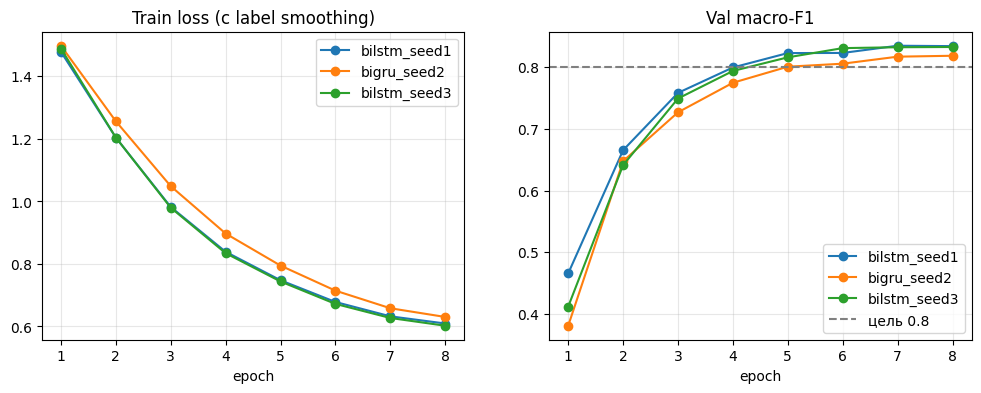

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories_v2.items():
    epochs_range = [h['epoch'] for h in history]
    axes[0].plot(epochs_range, [h['train_loss'] for h in history], 'o-', label=name)
    axes[1].plot(epochs_range, [h['val_f1'] for h in history], 'o-', label=name)
axes[0].set_title('Train loss (с label smoothing)')
axes[1].set_title('Val macro-F1')
axes[1].axhline(0.8, color='gray', linestyle='--', label='цель 0.8')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

In [42]:
results = [{'model': 'baseline (шаблон)', 'val F1': None, 'test F1': f1_baseline}]
val_probs_all, test_probs_all = [], []
for name, model in models_v2.items():
    val_probs, val_targets = predict_proba(model, val_loader_v2)
    test_probs, test_targets = predict_proba(model, test_loader_v2)
    val_probs_all.append(val_probs)
    test_probs_all.append(test_probs)
    results.append({
        'model': name,
        'val F1': f1_score(val_targets, val_probs.argmax(1), average='macro'),
        'test F1': f1_score(test_targets, test_probs.argmax(1), average='macro'),
    })

ensemble_val = torch.stack(val_probs_all).mean(0)
ensemble_test = torch.stack(test_probs_all).mean(0)
results.append({
    'model': 'ансамбль (среднее вероятностей)',
    'val F1': f1_score(val_targets, ensemble_val.argmax(1), average='macro'),
    'test F1': f1_score(test_targets, ensemble_test.argmax(1), average='macro'),
})
pd.DataFrame(results).round(4)

,model,val F1,test F1
0,baseline (шаблон),NaN,0.7204
1,bilstm_seed1,0.8340,0.8150
2,bigru_seed2,0.8178,0.8032
3,bilstm_seed3,0.8320,0.8240
4,ансамбль (среднее вероятностей),0.8475,0.8348


result: 0.8348 (было 0.7204)

                    precision    recall  f1-score   support

Extremely Negative      0.841     0.819     0.830       592
          Negative      0.790     0.809     0.799      1041
           Neutral      0.923     0.832     0.875       619
          Positive      0.775     0.842     0.807       947
Extremely Positive      0.886     0.841     0.863       599

          accuracy                          0.828      3798
         macro avg      0.843     0.829     0.835      3798
      weighted avg      0.831     0.828     0.828      3798



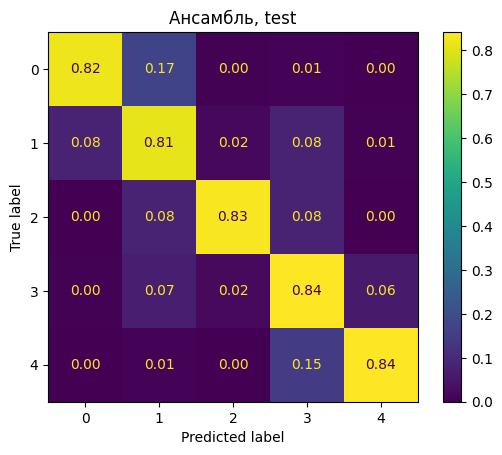

In [43]:
ensemble_pred = ensemble_test.argmax(1)
f1_improved = f1_score(test_targets, ensemble_pred, average='macro')
print(f'result: {f1_improved:.4f} (было {f1_baseline:.4f})\n')
print(classification_report(test_targets, ensemble_pred, target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(test_targets, ensemble_pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(5)).plot(values_format='.2f')
plt.title('Ансамбль, test')
plt.show()

Посмотрим, на какие слова смотрит attention (5 слов с наибольшим весом):

In [44]:
attn_model = models_v2['bilstm_seed1']
attn_model.eval()
for idx in [0, 1, 2, 3, 8, 13]:
    item = test_dataset_v2[idx]
    with torch.no_grad():
        logits = attn_model(item['tokens'][None].to(device), item['tokens_len'][None].to(device))
    weights = attn_model.last_attention[0].cpu()
    words = [itos_v2[i] for i in item['tokens']]
    top = weights.argsort(descending=True)[:5]
    print(f'{class_names[item["label"]]:>18} -> {class_names[logits.argmax().item()]:<18} | '
          + ', '.join(f'{words[j]} ({weights[j]:.2f})' for j in top))

Extremely Negative -> Negative           | empty (0.18), wegmans (0.14), supermarket (0.05), fearing (0.05), pictured (0.05)
          Positive -> Positive           | sanitizer (0.05), hand (0.05), url (0.05), for (0.04), pack (0.04)
Extremely Positive -> Extremely Positive | loved (0.65), ones (0.13), yourself (0.05), protect (0.04), and (0.03)
          Negative -> Negative           | panic (0.21), anxious (0.15), buying (0.05), newyork (0.04), hits (0.03)
Extremely Negative -> Extremely Negative | no (0.35), no (0.27), sick (0.10), worried (0.08), of (0.02)
Extremely Positive -> Extremely Positive | luck (0.46), wish (0.10), me (0.05), that (0.03), hand (0.02)


### Выводы

**Итоговые результаты (macro-F1 на test):**

| Модель | val F1 | test F1 |
|---|---|---|
| базовая (шаблон) | — | **0.720** |
| BiLSTM + attention, seed 1 | 0.834 | 0.815 |
| BiGRU + attention, seed 2 | 0.818 | 0.803 |
| BiLSTM + attention, seed 3 | 0.832 | 0.824 |
| **ансамбль из трёх моделей** | 0.848 | **0.835** |

Цель 0.8 достигнута: её превышает каждая улучшенная модель по отдельности, а ансамбль даёт прирост +0.115 к базовому решению.

**Базовая модель** (BiLSTM по последнему скрытому состоянию, 5000 слов, удалённые стоп-слова) даёт macro-F1 = 0.720 (accuracy 0.710). По графикам видно переобучение: accuracy на train к 10-й эпохе растёт до 0.884, а на test останавливается на 0.71 уже с 7-й эпохи; test loss минимален на 6-й эпохе (0.835) и дальше растёт до 0.905. Лучше всего модель распознаёт `Neutral` (F1 0.798), хуже всего — `Negative` (0.645) и `Positive` (0.683).

По матрице ошибок основная путаница — между соседними классами: 22% `Extremely Negative` уходит в `Negative`, 17% `Extremely Positive` — в `Positive`. Кроме того, 10–14% `Negative` и `Positive` путаются **между собой**, то есть модель ошибается в знаке тональности. Это прямое следствие удаления стоп-слов: вместе с ними пропадают `not`, `no`, `don't`, `very`, `too`, которые переворачивают или усиливают тональность.

**Что дало прирост:**
1. *Предобработка.* Сохранение отрицаний и усилителей, исправление кодировки апострофа и знаки `!`/`?` возвращают модели информацию, которая в базовой версии терялась ещё до обучения. У ансамбля путаница `Negative` ↔ `Positive` упала до 7–8%, `Extremely Negative` → `Negative` — с 22% до 17%, `Extremely Positive` → `Positive` — с 17% до 15%.
2. *Словарь.* Все слова с частотой ≥ 2 (19 325 токенов вместо 5000) — доля `<unk>` в test снизилась с 12.0% до 2.5%.
3. *Архитектура.* `pack_padded_sequence` убирает влияние паддинга, attention + max-pooling по всем шагам позволяют опираться на ключевые слова в любом месте твита. По примерам видно, что attention действительно выделяет оценочные слова: *loved* (вес 0.65) и *luck* (0.46) для `Extremely Positive`, *panic* и *anxious* для `Negative`, двойное *no* и *sick* для `Extremely Negative`.
4. *Обучение и выбор модели.* OneCycleLR, label smoothing и выбор эпохи по валидации: val F1 растёт до 7–8-й эпохи без провала, разрыв между val и test небольшой (0.01–0.02), то есть выбор эпохи по валидации не переобучен под test.
5. *Ансамбль.* Усреднение вероятностей трёх моделей добавляет +0.011 к лучшей одиночной модели (0.835 против 0.824). Все классы теперь распознаются с F1 от 0.799 (`Negative`) до 0.875 (`Neutral`).

**Почему не lemmatization / pymorphy2.** `pymorphy2` — морфологический анализатор для русского языка, а твиты на английском. Для английского можно было бы использовать лемматизацию NLTK/spaCy, но на тональность она влияет слабо, а формы вроде `panicking`/`panic` и так близки в обученных эмбеддингах.

**Что можно сделать дальше:** использовать предобученные эмбеддинги (GloVe Twitter) или дообучить трансформер (BERT/RoBERTa) — на этом датасете такие модели дают заметно больше, чем RNN, обученная с нуля.